# Assignment 10

Adaptive median filter compared with the plain median using PSNR, then Otsu thresholding.

Salt-and-pepper (density 0.2) is added to `sample_portrait.jpg`. Windows 3 and 7. Otsu is run on `sample_butterfly.jpg`, where the dark wings and the light petals separate.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# adaptive median vs plain median (PSNR), and Otsu threshold
# adaptive median is for salt-and-pepper, so that noise is added first

np.random.seed(2)


def adaptive_median(img, start, smax):
    out = img.copy()
    done = np.zeros(img.shape, dtype=bool)
    ws = start

    while ws <= smax:
        kernel = np.ones((ws, ws), np.uint8)
        zmin = cv2.erode(img, kernel, borderType=cv2.BORDER_REPLICATE)
        zmax = cv2.dilate(img, kernel, borderType=cv2.BORDER_REPLICATE)
        zmed = cv2.medianBlur(img, ws)
        zxy = img

        # cast to int, uint8 subtraction wraps around
        A1 = zmed.astype(np.int16) - zmin.astype(np.int16)
        A2 = zmed.astype(np.int16) - zmax.astype(np.int16)
        # level A: median sits strictly between min and max
        level_a = (A1 > 0) & (A2 < 0) & ~done

        B1 = zxy.astype(np.int16) - zmin.astype(np.int16)
        B2 = zxy.astype(np.int16) - zmax.astype(np.int16)
        # level B: keep the pixel if it is not an impulse, else take the median
        keep = level_a & (B1 > 0) & (B2 < 0)
        use_med = level_a & ~keep

        out[keep] = zxy[keep]
        out[use_med] = zmed[use_med]
        done[level_a] = True
        ws += 2

    if not np.all(done):
        zmed = cv2.medianBlur(img, smax)
        out[~done] = zmed[~done]
    return out


def add_salt_pepper(img, density):
    out = img.copy()
    rnd = np.random.rand(*img.shape)
    out[rnd < density / 2.0] = 0
    out[rnd > 1.0 - density / 2.0] = 255
    return out


def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10((255.0 ** 2) / mse)


def otsu_threshold(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    total = float(img.size)
    sum_all = np.dot(np.arange(256), hist)

    sum_b = 0.0
    w_b = 0.0
    best = -1.0
    thresh = 0

    for t in range(256):
        w_b += hist[t]
        if w_b == 0:
            continue
        w_f = total - w_b
        if w_f == 0:
            break
        sum_b += t * hist[t]
        mean_b = sum_b / w_b
        mean_f = (sum_all - sum_b) / w_f
        between = w_b * w_f * (mean_b - mean_f) ** 2
        if between > best:
            best = between
            thresh = t
    return thresh


def otsu_segment(img):
    t = otsu_threshold(img)
    out = np.zeros_like(img)
    # same rule as cv2 THRESH_BINARY: pixel > t becomes white
    out[img > t] = 255
    return out, t


salt and pepper image: sample_portrait.jpg (256, 256)
otsu image: sample_butterfly.jpg (388, 515)
filtering...
salt and pepper density = 0.2
PSNR noisy             12.04 dB
PSNR median 3x3     30.36 dB
PSNR median 7x7     32.61 dB
PSNR adaptive median   39.8 dB
Otsu threshold = 105


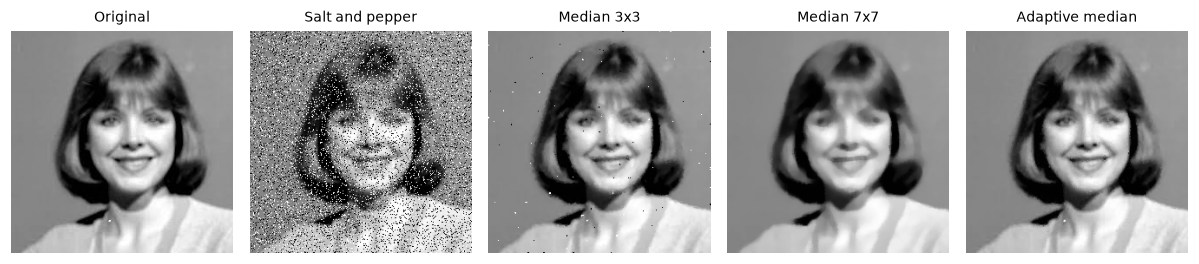

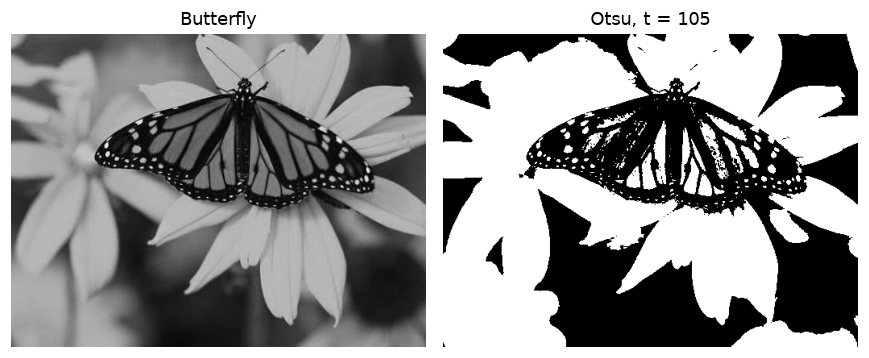

In [2]:
face_path = "sample_portrait.jpg"
otsu_path = "sample_butterfly.jpg"
start = 3
smax = 7
density = 0.2

img = cv2.imread(face_path, 0)
wing = cv2.imread(otsu_path, 0)
print("salt and pepper image:", face_path, img.shape)
print("otsu image:", otsu_path, wing.shape)

noisy = add_salt_pepper(img, density)
print("filtering...")
med_small = cv2.medianBlur(noisy, start)
med_big = cv2.medianBlur(noisy, smax)
amf = adaptive_median(noisy, start, smax)

print("salt and pepper density =", density)
print("PSNR noisy            ", round(psnr(img, noisy), 2), "dB")
print("PSNR median", str(start) + "x" + str(start), "   ", round(psnr(img, med_small), 2), "dB")
print("PSNR median", str(smax) + "x" + str(smax), "   ", round(psnr(img, med_big), 2), "dB")
print("PSNR adaptive median  ", round(psnr(img, amf), 2), "dB")

seg, t = otsu_segment(wing)
print("Otsu threshold =", t)

plt.figure(figsize=(11, 4))
titles = ["Original", "Salt and pepper",
          "Median " + str(start) + "x" + str(start),
          "Median " + str(smax) + "x" + str(smax),
          "Adaptive median"]
pics = [img, noisy, med_small, med_big, amf]
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(pics[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i], fontsize=9)
    plt.axis("off")
plt.tight_layout()

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(wing, cmap="gray", vmin=0, vmax=255)
plt.title("Butterfly")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(seg, cmap="gray", vmin=0, vmax=255)
plt.title("Otsu, t = " + str(t))
plt.axis("off")
plt.tight_layout()
plt.show()
